# TECNICAS DE APRENDIZAJE AUTOMATICO

## Prueba de progreso 3: Competición de datos sobre predecir el daño de terremotos.

##### **Usuario: AndrexDC**
##### **Rango actual: 1524**

### <u>Introducción</u>

#### **Predicción del daño sísmico en edificios**
En este trabajo se aborda un problema de aprendizaje automático aplicado a la evaluación de daños producidos por terremotos. El objetivo principal consiste en predecir el nivel de daño sufrido por distintos edificios a partir de información estructural, geográfica y constructiva.

El conjunto de datos utilizado proviene de la competición “Richter’s Predictor: Modeling Earthquake Damage” de la plataforma DrivenData. Este dataset contiene información de miles de edificios afectados por un terremoto en Nepal, incluyendo características como:

- Número de plantas.

- Antigüedad del edificio.

- Tipo de cimentación.

- Materiales de construcción.

- Tipo de tejado.

- Condiciones del terreno.

- Uso del edificio.

A partir de estas variables se pretende estimar el nivel de daño estructural sufrido por cada edificio.


#### **Variable objetivo: damage_grade**
La variable objetivo del problema es damage_grade, que representa el grado de daño sufrido por cada edificio tras el terremoto.

Esta variable toma valores ordinales:

- 1 → daño bajo
- 2 → daño medio
- 3 → daño severo

Por tanto, no se trata únicamente de categorías independientes, sino que existe un orden natural entre ellas. Esto convierte el problema en un caso especialmente interesante, ya que combina características tanto de clasificación como de regresión ordinal.

#### **Objetivo del trabajo**
El objetivo principal del proyecto es analizar el comportamiento de distintos algoritmos de aprendizaje automático para determinar cuáles son más adecuados para predecir el daño sísmico de los edificios.

#### **Metrica de evaluación**
Para comparar los distintos modelos utilizaremos la métrica F1-score con el parámetro average="micro".

Se utiliza esta configuración porque es la métrica establecida para evaluar las predicciones en la competición.

In [55]:
import numpy as np # Para trabajar con operaciones matemáticas y estructuras numéricas
import pandas as pd # Para trabajar con datasets
import matplotlib.pyplot as plt # Para representar gráficos

from sklearn.model_selection import train_test_split # Para dividir el dataset
from sklearn.preprocessing import StandardScaler # Para escalar los datos
from sklearn.metrics import f1_score # Para evaluar modelos

### <u>Carga de los datasets</u>
Cargamos los distintos archivos .csv que vamos a utilizar durante el proyecto.

In [56]:
# Carga de datasets
train_values = pd.read_csv("train_values.csv")
train_labels = pd.read_csv("train_labels.csv")

test_values = pd.read_csv("test_values.csv")

submission_format = pd.read_csv("submission_format.csv")

#### **Vista preliminar del dataset**

In [57]:
train_values.head()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,0
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,0
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,0


In [58]:
train_labels.head()

,building_id,damage_grade
0,802906,3
1,28830,2
2,94947,3
3,590882,2
4,201944,3


In [59]:
test_values.head()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,300051,17,596,11307,3,20,7,6,t,r,...,0,0,0,0,0,0,0,0,0,0
1,99355,6,141,11987,2,25,13,5,t,r,...,1,0,0,0,0,0,0,0,0,0
2,890251,22,19,10044,2,5,4,5,t,r,...,0,0,0,0,0,0,0,0,0,0
3,745817,26,39,633,1,0,19,3,t,r,...,0,0,1,0,0,0,0,0,0,0
4,421793,17,289,7970,3,15,8,7,t,r,...,0,0,0,0,0,0,0,0,0,0


### <u>Información general de los datasets</u>

#### **Dimensiones de los datos**

Comprobamos el número de filas y columnas de cada dataset.

In [60]:
print("train_values:", train_values.shape)
print("train_labels:", train_labels.shape)
print("test_values:", test_values.shape)

train_values: (260601, 39)
train_labels: (260601, 2)
test_values: (86868, 39)


#### **Tipos de datos**

Analizamos el tipo de cada columna.

In [61]:
train_values.info()

<class 'pandas.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 39 columns):
 #   Column                                  Non-Null Count   Dtype
---  ------                                  --------------   -----
 0   building_id                             260601 non-null  int64
 1   geo_level_1_id                          260601 non-null  int64
 2   geo_level_2_id                          260601 non-null  int64
 3   geo_level_3_id                          260601 non-null  int64
 4   count_floors_pre_eq                     260601 non-null  int64
 5   age                                     260601 non-null  int64
 6   area_percentage                         260601 non-null  int64
 7   height_percentage                       260601 non-null  int64
 8   land_surface_condition                  260601 non-null  str  
 9   foundation_type                         260601 non-null  str  
 10  roof_type                               260601 non-null  str  
 11  ground_floo

In [62]:
train_labels.info()

<class 'pandas.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 2 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   building_id   260601 non-null  int64
 1   damage_grade  260601 non-null  int64
dtypes: int64(2)
memory usage: 4.0 MB


In [63]:
test_values.info()

<class 'pandas.DataFrame'>
RangeIndex: 86868 entries, 0 to 86867
Data columns (total 39 columns):
 #   Column                                  Non-Null Count  Dtype
---  ------                                  --------------  -----
 0   building_id                             86868 non-null  int64
 1   geo_level_1_id                          86868 non-null  int64
 2   geo_level_2_id                          86868 non-null  int64
 3   geo_level_3_id                          86868 non-null  int64
 4   count_floors_pre_eq                     86868 non-null  int64
 5   age                                     86868 non-null  int64
 6   area_percentage                         86868 non-null  int64
 7   height_percentage                       86868 non-null  int64
 8   land_surface_condition                  86868 non-null  str  
 9   foundation_type                         86868 non-null  str  
 10  roof_type                               86868 non-null  str  
 11  ground_floor_type         

#### **Comprobación de valores nulos**

Verificamos si existen datos faltantes que puedan afectar al entrenamiento de los modelos.

In [64]:
# Valores nulos en train_values
print(train_values.isnull().sum())

# Valores nulos en train_labels
print(train_labels.isnull().sum())

# Valores nulos en test_values
print(test_values.isnull().sum())

building_id                               0
geo_level_1_id                            0
geo_level_2_id                            0
geo_level_3_id                            0
count_floors_pre_eq                       0
age                                       0
area_percentage                           0
height_percentage                         0
land_surface_condition                    0
foundation_type                           0
roof_type                                 0
ground_floor_type                         0
other_floor_type                          0
position                                  0
plan_configuration                        0
has_superstructure_adobe_mud              0
has_superstructure_mud_mortar_stone       0
has_superstructure_stone_flag             0
has_superstructure_cement_mortar_stone    0
has_superstructure_mud_mortar_brick       0
has_superstructure_cement_mortar_brick    0
has_superstructure_timber                 0
has_superstructure_bamboo       

#### **Comprobación de duplicados**

In [65]:
print("train_values:", train_values.duplicated().sum())

print("train_labels:", train_labels.duplicated().sum())

print("test_values:", test_values.duplicated().sum())

train_values: 0
train_labels: 0
test_values: 0


### <u>Unión de datasets</u>

Unimos las variables de entrada con la variable objetivo para poder trabajar en un único DataFrame.

De esta forma tenemos toda la información necesaria en una sola estructura de datos e identificamos de forma única cada edificio.

In [66]:
# Unimos las características de los edificios utilizando building_id como identificador común.
df_train = train_values.merge(train_labels, on="building_id")

# Vista del dataset completo
df_train.head()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,3


La columna building_id actúa como identificador único de cada edificio y permite relacionar correctamente las características estructurales con su correspondiente nivel de daño (damage_grade).

#### **Comprobación final del dataset**

In [67]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 40 columns):
 #   Column                                  Non-Null Count   Dtype
---  ------                                  --------------   -----
 0   building_id                             260601 non-null  int64
 1   geo_level_1_id                          260601 non-null  int64
 2   geo_level_2_id                          260601 non-null  int64
 3   geo_level_3_id                          260601 non-null  int64
 4   count_floors_pre_eq                     260601 non-null  int64
 5   age                                     260601 non-null  int64
 6   area_percentage                         260601 non-null  int64
 7   height_percentage                       260601 non-null  int64
 8   land_surface_condition                  260601 non-null  str  
 9   foundation_type                         260601 non-null  str  
 10  roof_type                               260601 non-null  str  
 11  ground_floo

In [68]:
df_train.describe()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
count,2.606010e+05,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,...,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000
mean,5.256755e+05,13.900353,701.074685,6257.876148,2.129723,26.535029,8.018051,5.434365,0.088645,0.761935,...,0.033626,0.008101,0.000940,0.000361,0.001071,0.000188,0.000146,0.000088,0.005119,2.238272
std,3.045450e+05,8.033617,412.710734,3646.369645,0.727665,73.565937,4.392231,1.918418,0.284231,0.425900,...,0.180265,0.089638,0.030647,0.018989,0.032703,0.013711,0.012075,0.009394,0.071364,0.611814
min,4.000000e+00,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.611900e+05,7.000000,350.000000,3073.000000,2.000000,10.000000,5.000000,4.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
50%,5.257570e+05,12.000000,702.000000,6270.000000,2.000000,15.000000,7.000000,5.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000
75%,7.897620e+05,21.000000,1050.000000,9412.000000,2.000000,30.000000,9.000000,6.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,1.052934e+06,30.000000,1427.000000,12567.000000,9.000000,995.000000,100.000000,32.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000


### <u>Análisis exploratorio de los datos</u>

Para comprender mejor la información con la que vamos a trabajar:

- Entender la estructura de los datos.
- Detectar patrones.
- Identificar posibles problemas.
- Analizar distribuciones.
- Estudiar relaciones entre variables.
- Obtener información útil antes del entrenamiento de modelos.

In [69]:
import seaborn as sns # Para crear gráficos estadísticos

#### **Analisis de cuántos edificios existen en cada nivel de daño.**

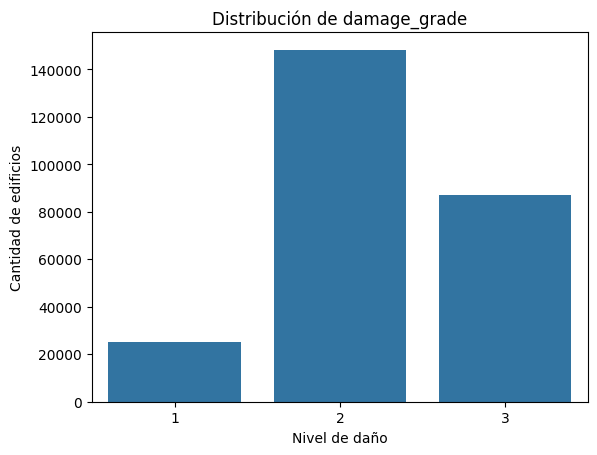

In [70]:
sns.countplot(x="damage_grade", data=df_train)

plt.title("Distribución de damage_grade")
plt.xlabel("Nivel de daño")
plt.ylabel("Cantidad de edificios")

plt.show()

#### **Analisis de la edad de los edificios**

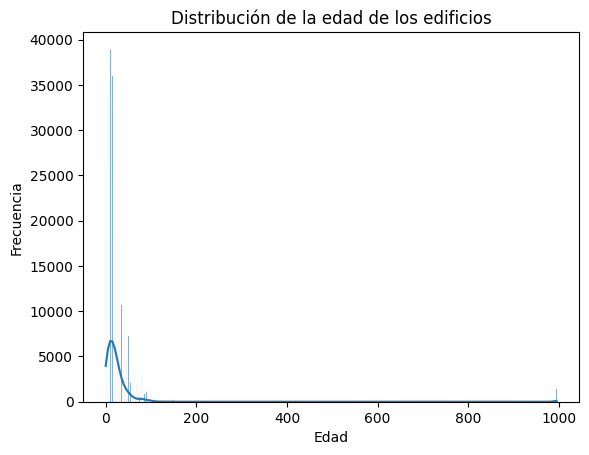

In [71]:
sns.histplot(df_train["age"], kde=True)

plt.title("Distribución de la edad de los edificios")
plt.xlabel("Edad")
plt.ylabel("Frecuencia")

plt.show()

#### **Analisis de la altura del edificio**

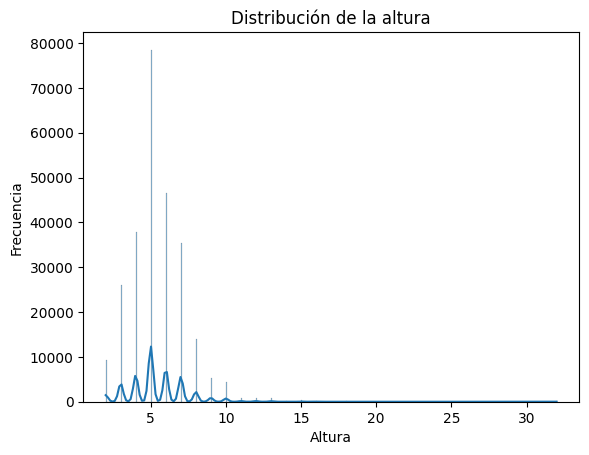

In [72]:
sns.histplot(df_train["height_percentage"], kde=True)

plt.title("Distribución de la altura")
plt.xlabel("Altura")
plt.ylabel("Frecuencia")

plt.show()

#### **Analisis del area del edificio**

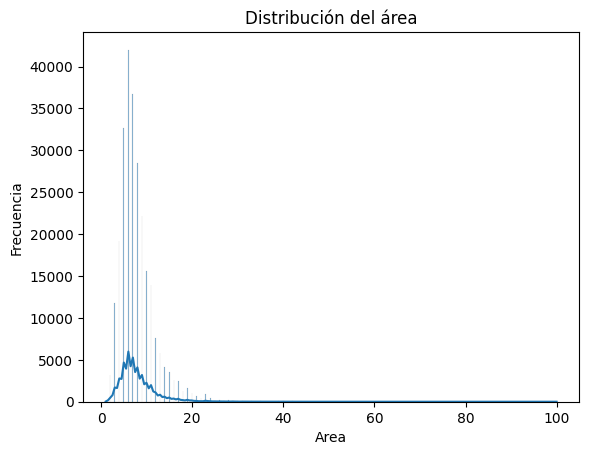

In [73]:
sns.histplot(df_train["area_percentage"], kde=True)

plt.title("Distribución del área")
plt.xlabel("Area")
plt.ylabel("Frecuencia")

plt.show()

#### **Matriz de correlación**

La matriz de correlación permite estudiar las relaciones lineales entre las variables numéricas del conjunto de datos.

Este análisis resulta útil para detectar posibles relaciones fuertes entre variables y conocer si existen características que aportan información similar.

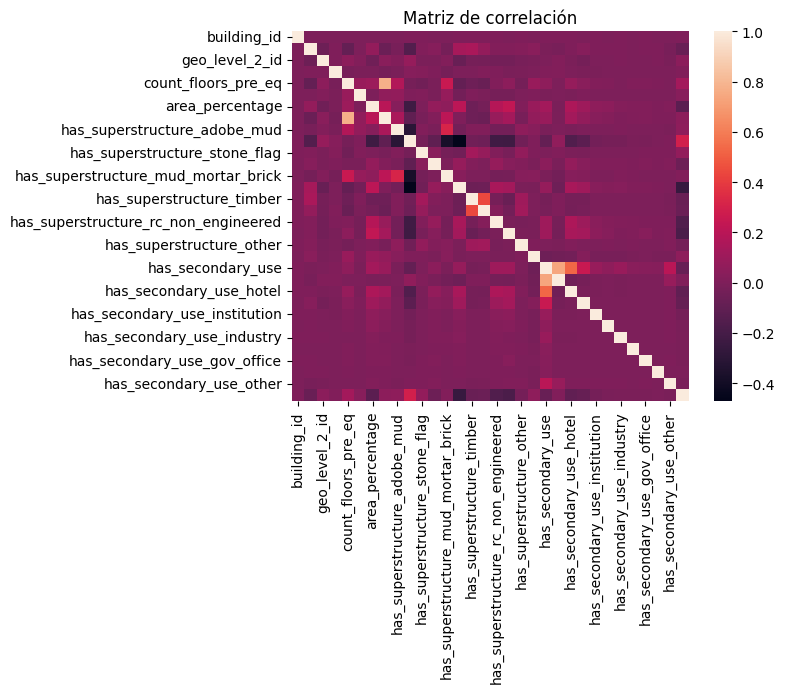

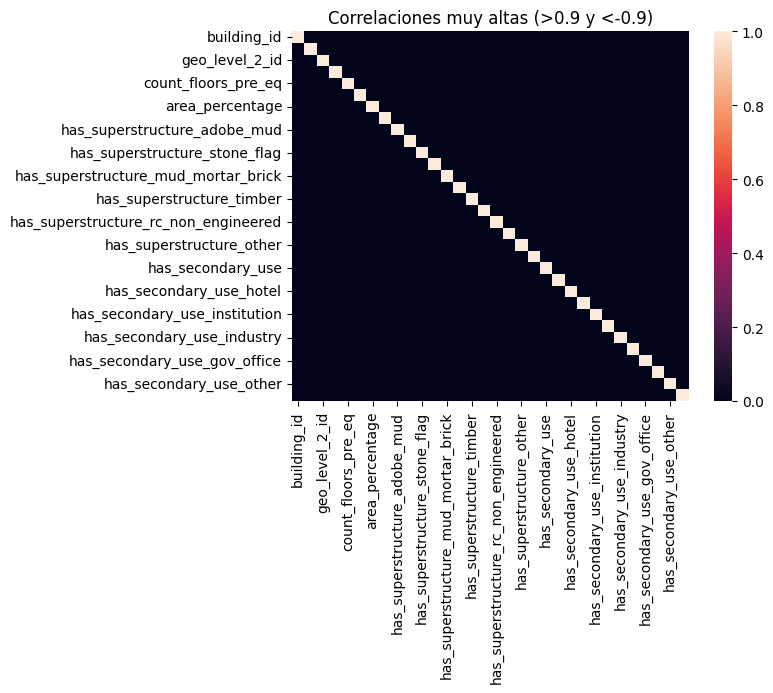

In [74]:
corr = df_train.corr(numeric_only=True)

sns.heatmap(corr)
plt.title("Matriz de correlación")
plt.show()

# Para ver correlaciones fuertes
sns.heatmap(corr.abs() > 0.9)
plt.title("Correlaciones muy altas (>0.9 y <-0.9)")
plt.show()

#### **Analisis de variables geograficas**

Diferentes zonas pueden tener:

- Distinta intensidad sísmica.

- Diferente tipo de suelo.

- Diferentes materiales de construcción.

- Normativas distintas.

Estas variables pueden aportar muchísima información al modelo.

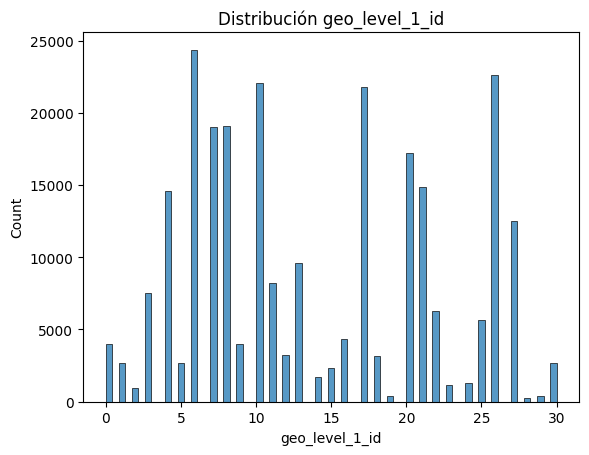

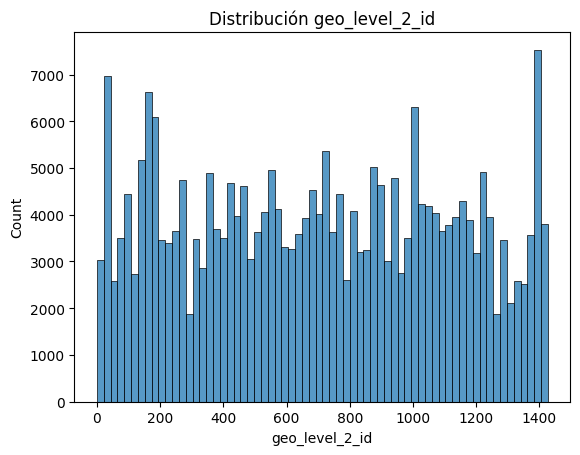

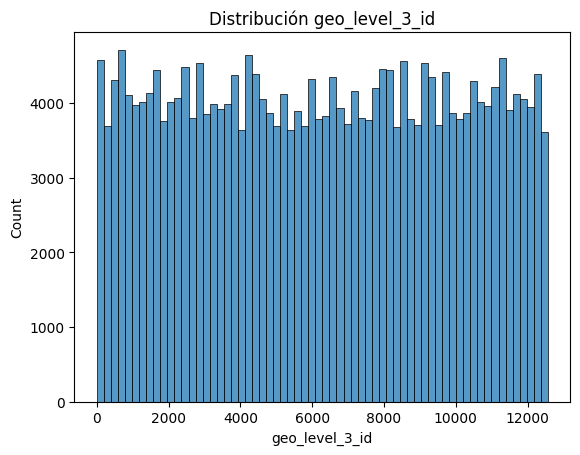

In [75]:
sns.histplot(df_train["geo_level_1_id"])
plt.title("Distribución geo_level_1_id")
plt.show()

sns.histplot(df_train["geo_level_2_id"])
plt.title("Distribución geo_level_2_id")
plt.show()

sns.histplot(df_train["geo_level_3_id"])
plt.title("Distribución geo_level_3_id")
plt.show()

#### **Conclusión final del analisis** 

Despues de hacer este analisis hemos visto:

- En la matriz de correlaciones que no hay variables que tengan una fuerte correlación positiva o negativa entre variables.

- El dataset esta algo desbalanceado.

### <u>Preprocesamiento de datos</u>

Separamos las variables predictoras (x) y variable objetivo (y)

In [76]:
# Variables predictoras
x = df_train.drop("damage_grade", axis=1) # Información del edificio

# Variable objetivo
y = df_train["damage_grade"] # Nivel de daño

#### **Conversión de variables categóricas**

Machine Learning trabaja con números, por lo que es necesitamos transformar esas categorías a formato numérico. Para ello aplicamos pd.get_dummies().

Este procedimiento transforma cada categoría en una nueva columna binaria, indicando mediante valores 0 y 1 si cada registro pertenece o no a una determinada categoría.

Como este tipo de variables las tenemos en el entrenamiento (x) y en el test, lo aplicamos en estas

In [77]:
# Transformamos las variables categóricas
x = pd.get_dummies(x)

# Transformación las variables categoricas del conjunto de test.
test_values_encoded = pd.get_dummies(test_values)

#### **División en entrenamiento y validación**

Se reserva el 80 % de los datos para entrenar los modelos y el 20 % restante para evaluar su capacidad de generalización.

Además, se utiliza random_state=42 para garantizar que la división sea reproducible y que los resultados puedan compararse utilizando siempre la misma partición.

In [78]:
x_train, x_valid, y_train, y_valid = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

#### **Escalado de variables**

Aplicamos StandardScaler para normalizar las variables numéricas en aquellos modelos sensibles a la escala de los datos.

El escalado transforma las variables para que tengan media 0 y desviación típica 1, evitando que variables con magnitudes grandes dominen el aprendizaje del modelo.

In [79]:
scaler = StandardScaler()

# Calculamos los parámetros de escalado únicamente con entrenamiento.
x_train_scaled = scaler.fit_transform(x_train)

# Calculamos los parámetros de escalado únicamente con validación.
x_valid_scaled = scaler.transform(x_valid)

Añadimos este from para ayudar a la busqueda del mejor hiperparametro de cada modelo

In [80]:
from sklearn.model_selection import GridSearchCV

### <u>Modelos a utilizar</u>

En esta práctica no se han utilizado modelos de aprendizaje no supervisado ni modelos de regresión debido al problema planteado y del propio dataset.

Por un lado, no se han empleado técnicas no supervisadas porque el conjunto de datos dispone de una variable objetivo claramente definida (damage_grade). El objetivo principal consiste en predecir el nivel de daño sísmico de cada edificio a partir de ejemplos previamente etiquetados, por lo que se trata de un problema de aprendizaje supervisado.

Por otro lado, tampoco se han utilizado modelos de regresión ya que la variable objetivo no representa un valor numérico continuo, sino categorías que indican niveles de daño estructural.

### **Modelos de clasificacion**

#### 1. KNN

In [81]:
# Importamos el modelo KNN para clasificación
from sklearn.neighbors import KNeighborsClassifier

##### <u>Sin busqueda de hiperparametro</u>

In [82]:
knn_clas = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)

 **Entrenamiento**

In [83]:
# Entrena el modelo con datos de entrenamiento escalados y las etiquetas de calidad del vino
knn_clas.fit(x_train_scaled, y_train) 

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",-1


**Predecimos**

In [84]:
# Predecimos las clases del conjunto de prueba
y_pred_knn_clas = knn_clas.predict(x_valid_scaled)

**Evaluamos**

In [85]:
#  Evaluamos el modelo unicmente con F1 micro que es como se trabaja en la competición
f1_knn = f1_score(
    y_valid,
    y_pred_knn_clas,
    average="micro"
)

print("F1 Micro KNN:", f1_knn)

F1 Micro KNN: 0.6270792962529499


##### Con hiperparametrización

In [86]:
# Posibles hiperparámetros

"""param_grid = {
    "n_neighbors": [3, 5, 7],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"]
}

# Grid Search
grid_knn = GridSearchCV(
    estimator=KNeighborsClassifier(n_jobs=-1),
    param_grid=param_grid,
    scoring="f1_micro",
    cv=3,
    n_jobs=-1
)"""

'param_grid = {\n    "n_neighbors": [3, 5, 7],\n    "weights": ["uniform", "distance"],\n    "metric": ["euclidean", "manhattan"]\n}\n\n# Grid Search\ngrid_knn = GridSearchCV(\n    estimator=KNeighborsClassifier(n_jobs=-1),\n    param_grid=param_grid,\n    scoring="f1_micro",\n    cv=3,\n    n_jobs=-1\n)'

**Entrenamos**

In [87]:
# Entrenamiento búsqueda hiperparámetros
"""grid_knn.fit(x_train_scaled, y_train)"""

'grid_knn.fit(x_train_scaled, y_train)'

**Predecimos**

In [88]:
# Predicción
"""y_pred_knn_clas_hiper = grid_knn.predict(x_valid_scaled)"""

'y_pred_knn_clas_hiper = grid_knn.predict(x_valid_scaled)'

**Evaluamos**

In [89]:
"""f1_knn_hiper = f1_score(
    y_valid,
    y_pred_knn_clas_hiper,
    average="micro"
)

print("F1 Micro KNN:", f1_knn_hiper)"""

'f1_knn_hiper = f1_score(\n    y_valid,\n    y_pred_knn_clas_hiper,\n    average="micro"\n)\n\nprint("F1 Micro KNN:", f1_knn_hiper)'

En este modelo no hemos sacado el mejor hiperparametro ya que al tener un gran numero de variables es un proceso que tarda excesivamente, por lo que se ha optado por utilizar solamente parametros bases.

##### **Conclusion de KNN para este dataframe**

KNN no es buena opcion para trabajar con este dataframe debido a que al contener una cantidad elevada de variables/columnas tarda excesivamente en ejecutarse la hiperparametrización para tener sus mejores parametros.

#### 2. Naive Bayes (GaussianNB)

In [90]:
# Importamos Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB

##### <u>Sin busqueda de hiperparametro</u>

In [91]:
nb = GaussianNB() # Se inicializa el clasificador

In [92]:
nb.fit(x_train_scaled, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


**Predecimos**

In [93]:
y_pred_nb = nb.predict(x_valid_scaled)

**Evaluamos**

In [94]:
f1_nb = f1_score(
    y_valid,
    y_pred_nb,
    average="micro"
)

print("F1 Micro Naive Bayes:", f1_nb)

F1 Micro Naive Bayes: 0.41138888355940983


En este modelo no hemos sacado el mejor hiperparametro ya que no disponemos de gran cantidad de hiperparametros, ademas de no ser de gran importancia los que tiene.

#### **Conclusion de Naive Bayes para este dataframe**

El uso de Naive Bayes no es una buena opcion para este dataset debido al valor tan bajo que nos da de F1-micro

### 3. SVM

In [95]:
# Importamos el modelo SVM para Clasificacion
from sklearn.svm import SVC

##### <u>Sin hiperparametrización</u>

In [96]:
"""svm_clas = SVC(kernel='rbf') # Se inicializa el clasificador"""

"svm_clas = SVC(kernel='rbf') # Se inicializa el clasificador"

In [97]:
"""svm_clas.fit(x_train_scaled, y_train)"""

'svm_clas.fit(x_train_scaled, y_train)'

**Predecimos**

In [98]:
"""y_pred_svm_clas = svm_clas.predict(x_valid_scaled)"""

'y_pred_svm_clas = svm_clas.predict(x_valid_scaled)'

**Evaluamos**

In [99]:
# Evaluamos el modelo usando métricas de clasificación
"""print(classification_report(y_valid, y_pred_svm_clas, labels=svm_clas.classes_, zero_division=0))"""

'print(classification_report(y_valid, y_pred_svm_clas, labels=svm_clas.classes_, zero_division=0))'

##### **Conclusion de SVM para este dataframe**

SVM no es buena opcion para trabajar con este dataframe debido a que al contener una cantidad elevada de variables/columnas tarda excesivamente en ejecutarse incluido el modelo base

#### 4. Arbol de decisión

In [100]:
from sklearn.tree import DecisionTreeClassifier

##### <u>Sin la busqueda de hiperparametro</u>

In [101]:
# Creamos el modelo de Árbol de Decisión
tree_clas = DecisionTreeClassifier(random_state=42)

**Entrenamos**

In [102]:
# Entrenamos el modelo con los datos de entrenamiento
tree_clas.fit(x_train, y_train)  # No utilizamos los valores escalado

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

**Predecimos**

In [103]:
# Predecimos la calidad de los vinos en el conjunto de prueba
y_pred_tree = tree_clas.predict(x_valid)

**Evaluamos**

In [104]:
f1_tree = f1_score(
    y_valid,
    y_pred_tree,
    average="micro"
)

print("F1 Micro Árbol:", f1_tree)

F1 Micro Árbol: 0.6453061146179083


##### <u>Con busqueda de hiperparametro</u>

In [105]:
param_grid = {"max_depth": range(1,20), # Numero maximo de niveles en el arbol
              "min_samples_split": [2, 4, 6], #  Numero minimo de muestras necesarias para dividir un nodo
              "min_samples_leaf": [8, 12, 16], # Numero minimo de muestras requeridas en cada nodo hoja
            }

grid_tree = GridSearchCV(
    estimator=tree_clas, 
    param_grid=param_grid,
    cv=4,
    scoring="f1_micro",
    n_jobs=-1
)

**Entrenamos**

In [106]:
grid_tree.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': range(1, 20), 'min_samples_leaf': [8, 12, ...], 'min_samples_split': [2, 4, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_micro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displaye

**Predecimos**

In [107]:
# Predicción
y_pred_tree_hiper = grid_tree.predict(x_valid)

**Evaluamos**

In [108]:
f1_tree_hiper = f1_score(
    y_valid,
    y_pred_tree_hiper,
    average="micro"
)

print("F1 Micro Árbol:", f1_tree_hiper)

F1 Micro Árbol: 0.7069511329406574


#### 4.2. Arbol de decision con Bagging

In [109]:
from sklearn.ensemble import BaggingClassifier

##### <u>Sin busqueda de hiperparametro</u>

In [110]:
# Modelo Bagging
bagging_clas = BaggingClassifier(
    estimator=tree_clas,
    n_estimators=50,
    max_samples=0.8,
    random_state=42,
    n_jobs=-1
)

**Entrenamos**

In [111]:
# Entrenamiento
bagging_clas.fit(x_train, y_train)

,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...ndom_state=42)
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",50
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",0.8
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary `... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


**Predecimos**

In [112]:
# Predicción
y_pred_bagging = bagging_clas.predict(x_valid)

**Evaluamos**

In [113]:
f1_bagging = f1_score(
    y_valid,
    y_pred_bagging,
    average="micro"
)

print("F1 Micro Bagging:", f1_bagging)

F1 Micro Bagging: 0.7269814470175169


##### <u>Con busqueda de hiperparametro</u>

In [114]:
# Utilizando los hiperparámetros del mejor arbol
tree_best = DecisionTreeClassifier(max_depth=19, min_samples_leaf=16, random_state=42)

# Modelo Bagging
bagging_model = BaggingClassifier(
    estimator=tree_best,
    random_state=42,
    n_jobs=-1
)

# Hiperparametros a probar
param_grid_gab = {
    "n_estimators": [100, 200],
    "max_samples": [0.6, 0.8, 1.0]
}

# Buscamos la combinación de hiperparámetros que da el mejor F1-micro mediante validación cruzada.
bag_hiper = GridSearchCV(
    estimator=bagging_model, 
    param_grid=param_grid_gab,
    cv=3,
    scoring="f1_micro",
    n_jobs=-1
)

**Entrenamos**

In [115]:
bag_hiper.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",BaggingClassi...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_samples': [0.6, 0.8, ...], 'n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_micro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displaye

**Predecimos**

In [116]:
y_pred_bagging_hiper = bag_hiper.predict(x_valid)

**Evaluamos**

In [117]:
f1_bagging_hiper = f1_score(
    y_valid,
    y_pred_bagging_hiper,
    average="micro"
)

print("F1 Micro Bagging Hiperparametrizado:", f1_bagging_hiper)

F1 Micro Bagging Hiperparametrizado: 0.7322960035302469


##### **Conclusion de Árbol de decisión para este dataframe**

El árbol de decisión obtiene buenos resultados en la clasificación del daño sísmico y presenta una gran ventaja en interpretabilidad, ya que permite comprender fácilmente cómo toma las decisiones el modelo.

Además, este algoritmo no requiere escalado de variables y es capaz de manejar relaciones complejas entre características numéricas y categóricas.

Sin embargo, los árboles de decisión tienden al overfitting cuando la profundidad es demasiado elevada, por lo que ha sido necesario ajustar el hiperparámetro max_depth mediante validación cruzada.

#### 6. Random Forest

In [118]:
from sklearn.ensemble import RandomForestClassifier

##### <u>Sin busqueda de hiperparametro</u>

In [119]:
# Creamos el modelo estandar para Random Forest
rf_clf = RandomForestClassifier(random_state = 42)

**Entrenamos**

In [120]:
# Entrenamos el modelo
rf_clf.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

**Predecimos**

In [121]:
# Predicción
y_pred_rf = rf_clf.predict(x_valid)

**Evaluamos**

In [122]:
f1_rf = f1_score(
    y_valid,
    y_pred_rf,
    average="micro"
)

print("F1 Micro Random Forest:", f1_rf)

F1 Micro Random Forest: 0.717407570844765


##### <u>Con busqueda de hiperparametro</u>

In [123]:
# Hiperparametros a probar
param_grid_rf = {
    "n_estimators": [200, 300],
    "max_depth": [10, 15, 20, None]
}
        
rf_clas_hiper = GridSearchCV(
    estimator= rf_clf,
    param_grid=param_grid_rf,
    scoring="f1_micro",
    cv=4,
    n_jobs=-1
)

**Entrenamos**

In [124]:
# Entrenamos el modelo
rf_clas_hiper.fit(x_train, y_train) # Como deriva de los arboles tampoco se usa el escalado

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [10, 15, ...], 'n_estimators': [200, 300]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_micro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- 

**Predecimos**

In [125]:
# Predicción
y_pred_rf_hiper = rf_clas_hiper.predict(x_valid)

**Evaluamos**

In [126]:
f1_rf_hiper = f1_score(
    y_valid,
    y_pred_rf_hiper,
    average="micro"
)

print("F1 Micro Random Forest Hiperparametrizado:", f1_rf_hiper)

F1 Micro Random Forest Hiperparametrizado: 0.7193069971796396


### <u>Comparacion entre todos los modelos</u>

Una vez entrenados y evaluados los diferentes algoritmos, recopilamos sus puntuaciones F1-micro en un único DataFrame.

Ordenamos los resultados de mayor a menor puntuación para identificar qué modelo obtiene el mejor rendimiento sobre el conjunto de validación.

In [127]:
resultados = pd.DataFrame({
    "Modelo": [
        "KNN",
        "Naive Bayes",
        "Decision Tree",
        "Decision Tree Hiperparametrizado",
        "Decision Tree Bagging",
        "Decision Tree Hiperparametrizado + Bagging",
        "Random Forest",
        "Random Forest Hiperparametrizado"
    ],
    "F1-score": [
        f1_knn,
        f1_nb,
        f1_tree,
        f1_tree_hiper,
        f1_bagging,
        f1_bagging_hiper,
        f1_rf,
        f1_rf_hiper
    ]
})

resultados = resultados.sort_values(by="F1-score", ascending=False)

resultados

,Modelo,F1-score
5,Decision Tree Hiperparametrizado + Bagging,0.732296
4,Decision Tree Bagging,0.726981
7,Random Forest Hiperparametrizado,0.719307
6,Random Forest,0.717408
3,Decision Tree Hiperparametrizado,0.706951
2,Decision Tree,0.645306
0,KNN,0.627079
1,Naive Bayes,0.411389


Hacemos la prediccion con el mejor modelo y los datos a validar del principio

In [128]:
test_predictions = bag_hiper.predict(test_values_encoded)

### <u>Crear CSV a subir</u>

Una vez identificado el modelo seleccionado, lo utilizamos para realizar las predicciones sobre el conjunto de datos de test.

Finalmente, generamos un archivo CSV con dos columnas: building_id y damage_grade.

Este archivo sigue la estructura solicitada por la competición y contiene las predicciones que se utilizarán para la evaluación final.

In [129]:
submission = pd.DataFrame({
    "building_id": test_values["building_id"],
    "damage_grade": test_predictions
})

submission.to_csv("submission.csv", index=False)